# 01 - Data Acquisition & Exploratory Data Analysis
**Heart Disease UCI (Cleveland)** - predict presence of heart disease from 13 clinical attributes.

The notebook is the *orchestration layer*; all logic lives in `src/` so it is reused by the training pipeline, CI and the API.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: D:\BITS\Semester-3\MLOps\MLOPS_Webinar1\heart-disease-mlops


## 1. Download the raw data
`src/data/load_data.py` downloads `processed.cleveland.data` from the UCI repository only if it is not already present. The file is headerless and uses `?` for missing values.

In [2]:
from src.data.load_data import download_dataset, load_raw_data
download_dataset()
raw = load_raw_data()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


## 2. Validate schema & clinical ranges

In [4]:
from src.config import RAW_COLUMNS
from src.data.validate_data import validate_data
validate_data(raw, RAW_COLUMNS, target_column='num', target_values=range(5))

{'rows': 303,
 'columns': 14,
 'missing_values': {'ca': 4, 'thal': 2},
 'duplicate_rows': 0,
 'out_of_range': {}}

## 3. Clean
* `?` -> NaN, numeric coercion, duplicate removal
* `num` (0-4) -> binary `target` (0 = absent, 1 = present)
* The few NaNs in `ca` (4) and `thal` (2) are **kept** and imputed *inside* the sklearn pipeline, so imputation is learned on training folds only (no leakage) and is applied identically at serving time.

In [5]:
from src.data.clean_data import run_cleaning
clean, report = run_cleaning()
report

{'rows': 303,
 'columns': 14,
 'missing_values': {'ca': 4, 'thal': 2},
 'duplicate_rows': 0,
 'out_of_range': {},
 'class_balance': {'0': 164, '1': 139}}

In [6]:
clean.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 4. Visual EDA

In [7]:
from src.eda.run_eda import run_eda
figures, summary = run_eda(clean)
summary

{'shape': [303, 14],
 'class_balance': {'0': 164, '1': 139},
 'missing_values': {'ca': 4, 'thal': 2},
 'target_correlation': {'thal': 0.526,
  'ca': 0.46,
  'exang': 0.432,
  'oldpeak': 0.425,
  'thalach': -0.417,
  'cp': 0.414,
  'slope': 0.339,
  'sex': 0.277,
  'age': 0.223,
  'restecg': 0.169,
  'trestbps': 0.151,
  'chol': 0.085,
  'fbs': 0.025}}

**01_class_balance.png**

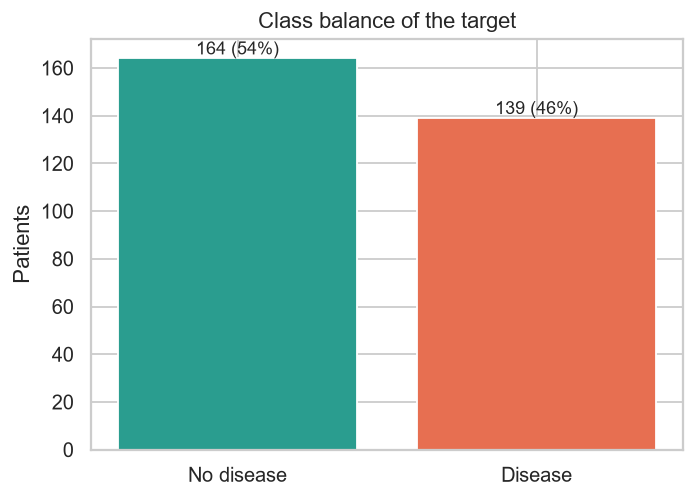

**02_numeric_histograms.png**

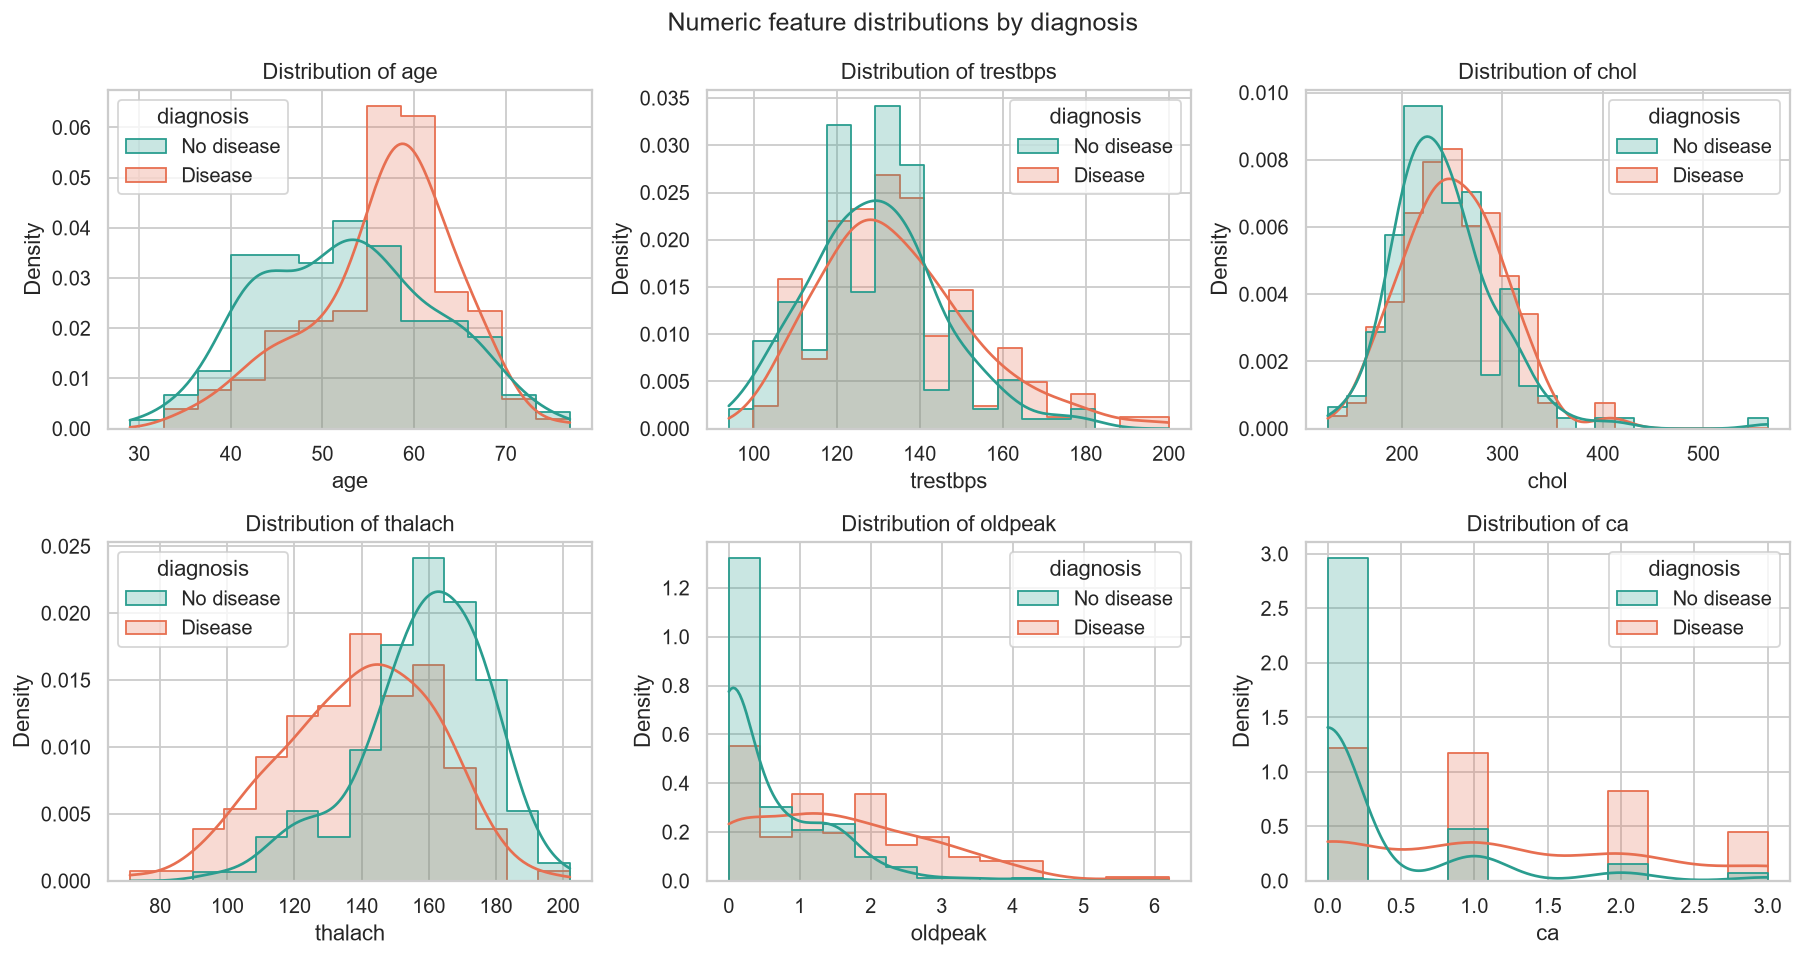

**03_categorical_disease_rate.png**

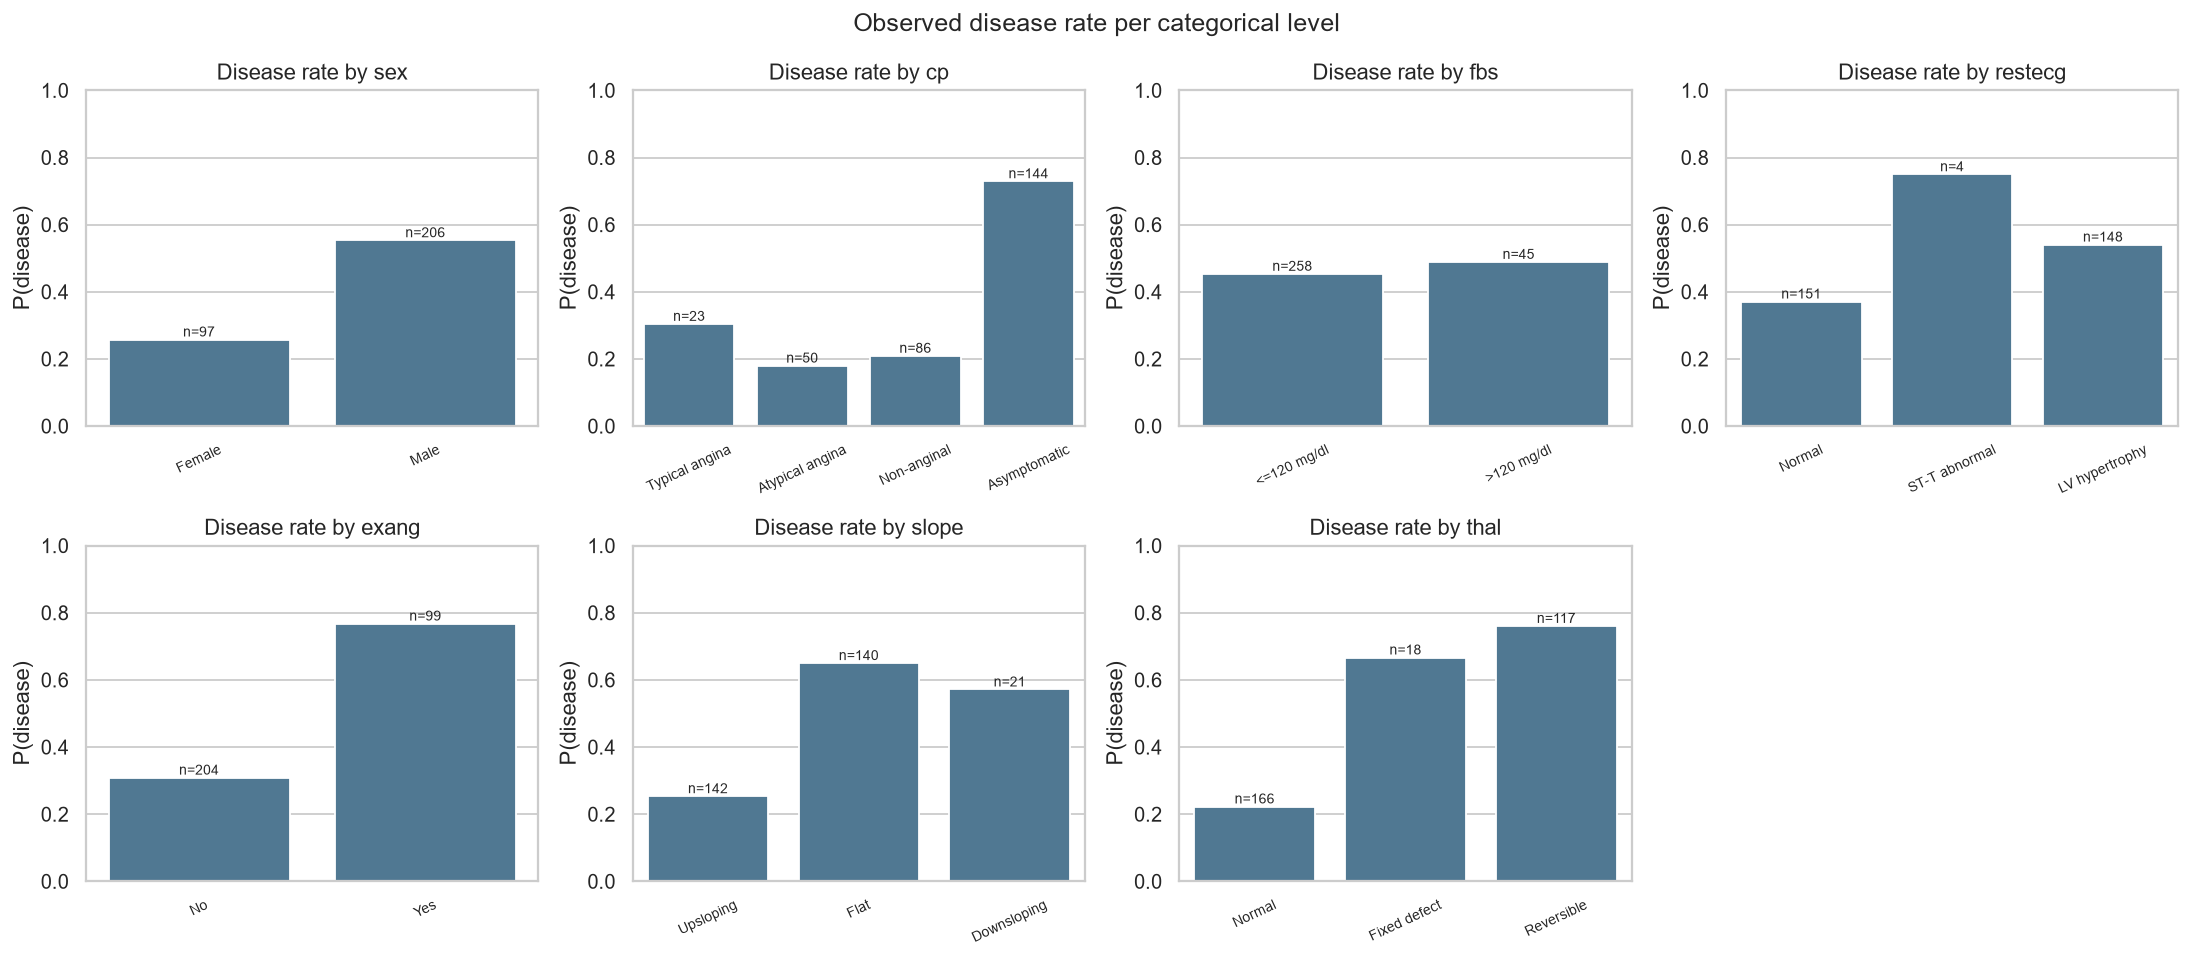

**04_correlation_heatmap.png**

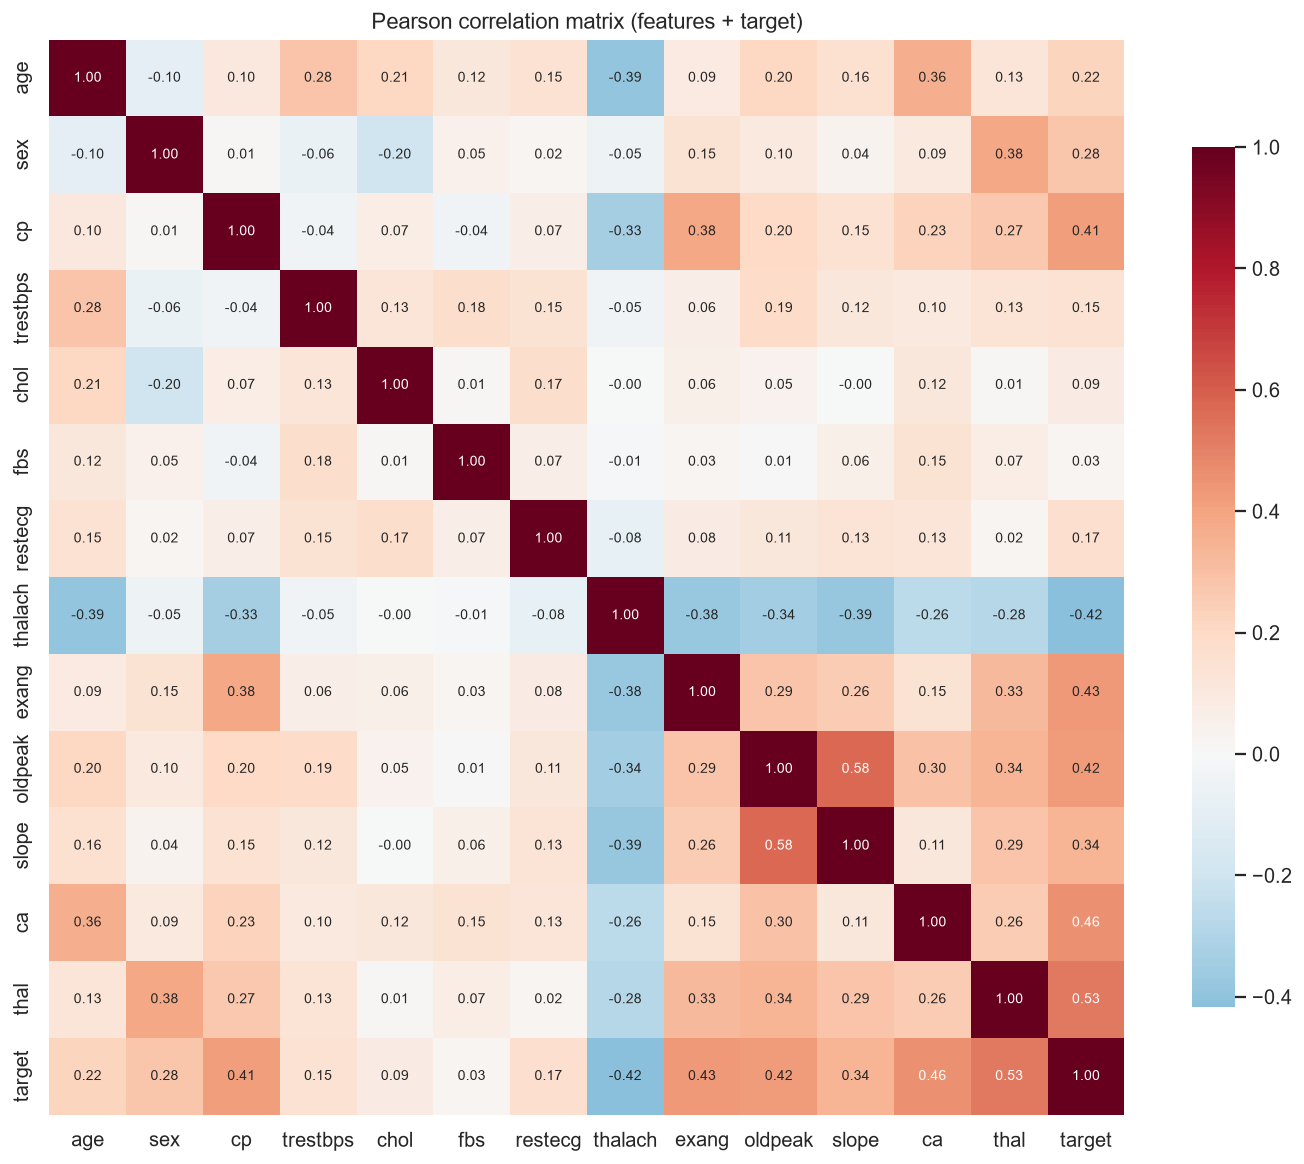

**05_boxplots.png**

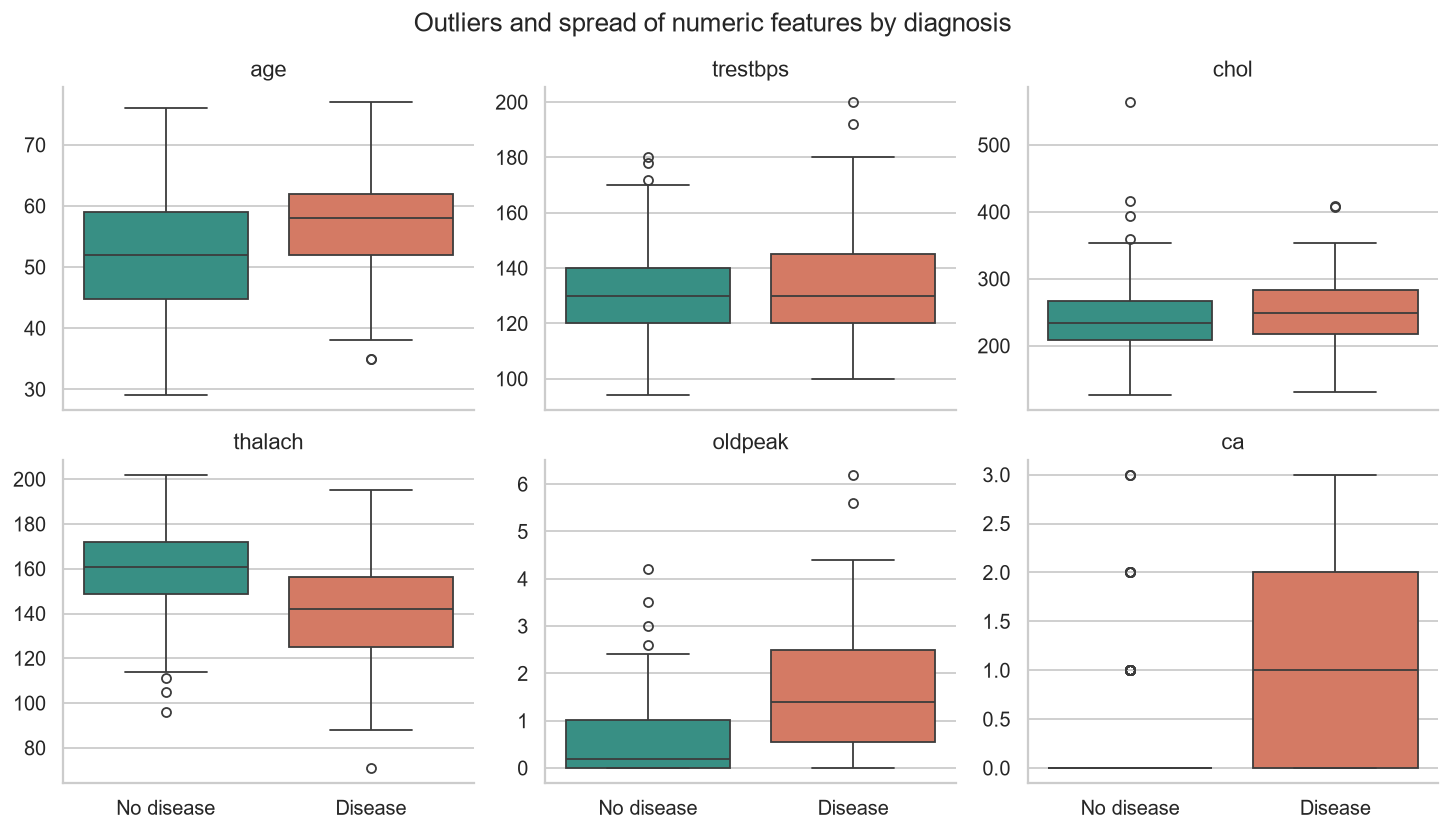

**06_missing_values.png**

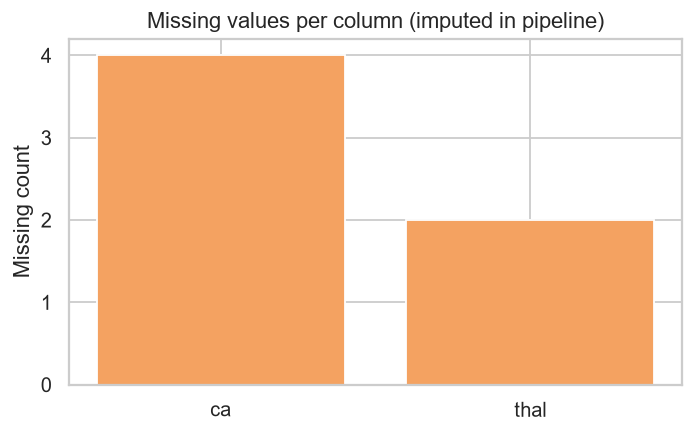

In [8]:
for f in figures:
    display(Markdown(f'**{f.name}**')); display(Image(filename=str(f)))

## 5. Findings that drive modelling choices
* **Class balance** 164 vs 139 (54% / 46%) - mildly imbalanced, so stratified splits/CV are used and `class_weight` is tuned; accuracy is complemented with recall and ROC-AUC.
* **Strongest signals**: `thal`, `ca`, `exang`, `oldpeak`, `thalach` (negative), `cp` (asymptomatic chest pain has ~73% disease rate). `chol` and `fbs` are weak on their own.
* `cp`, `restecg`, `slope`, `thal` are **nominal** codes - their numeric order is meaningless, so they are one-hot encoded rather than scaled.
* `thalach` falls with age, so an age-normalised feature `hr_pct_of_max = thalach / (220 - age)` is engineered.
* Numeric features are on very different scales (chol ~250 vs oldpeak ~1) and have a few outliers (chol 564), so they are standardised; tree models are insensitive to this, logistic regression is not.